In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

project = Path.cwd()
if not (project / "data").is_dir():
    project = project.parent

dev = pd.read_csv(
    project / "data/processed/development.csv",
    dtype={"ID": "string"},
    low_memory=False
)

target = "Rej_and_cut_Piece"
figures = project / "reports/figures"
figures.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

print("Development records:", len(dev))
print("Development IDs:", dev["ID"].nunique())
print("Recorded zero targets:", dev[target].eq(0).sum())

display(
    dev[target].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Development records: 16139
Development IDs: 756
Recorded zero targets: 3587


count    16139.000000
mean       105.305099
std        487.760314
min          0.000000
25%          3.000000
50%         17.000000
75%         56.000000
90%        169.000000
95%        297.000000
99%       2074.960000
max      11353.000000
Name: Rej_and_cut_Piece, dtype: float64

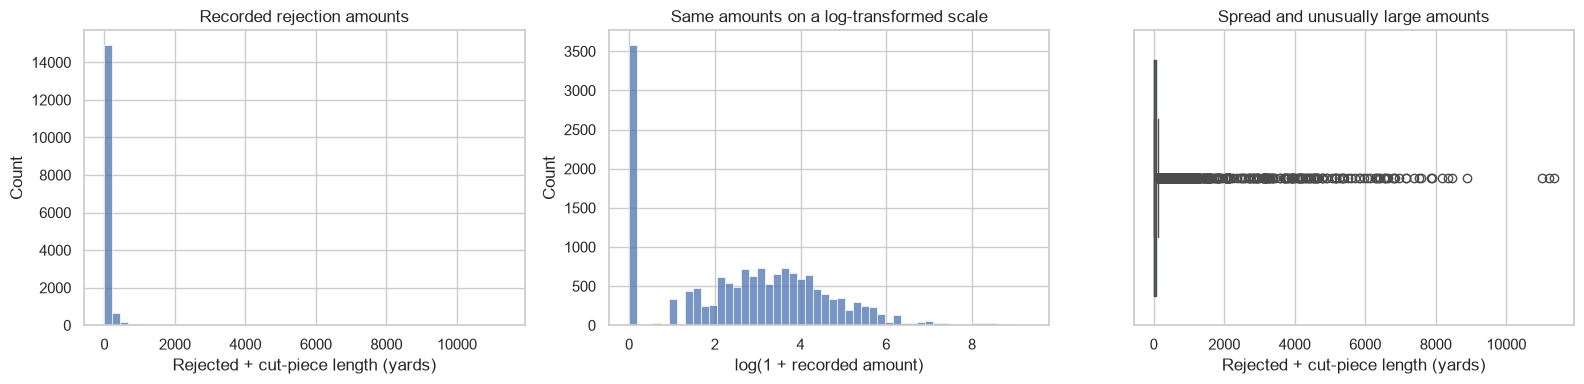

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(data=dev, x=target, bins=50, ax=axes[0])
axes[0].set_title("Recorded rejection amounts")
axes[0].set_xlabel("Rejected + cut-piece length (yards)")

sns.histplot(
    x=np.log1p(dev[target]),
    bins=50,
    ax=axes[1]
)
axes[1].set_title("Same amounts on a log-transformed scale")
axes[1].set_xlabel("log(1 + recorded amount)")

sns.boxplot(x=dev[target], ax=axes[2])
axes[2].set_title("Spread and unusually large amounts")
axes[2].set_xlabel("Rejected + cut-piece length (yards)")

fig.tight_layout()
fig.savefig(figures / "eda_target_distribution.png", dpi=160)
plt.show()

Non-missing entries that failed numeric conversion:


Req_Finish_Fabrics      0
Fabric_Allowance        0
Shrink_allow            0
Req_grey_fabric         0
Req_beam_length(yds)    0
epi                     0
ppi                     0
dtype: int64

,count,mean,std,min,25%,50%,75%,max
Req_Finish_Fabrics,16139.0,9263.920069,20144.770344,50.00000,1400.000000,3000.000000,6699.500000,172800.0000
Fabric_Allowance,16139.0,9.047303,3.515921,5.00000,7.000000,8.000000,9.800000,44.0000
Shrink_allow,16139.0,13.354727,2.930299,7.20000,11.200000,14.000000,14.600000,37.0000
Req_grey_fabric,16139.0,10001.458607,21697.716781,62.50000,1581.920904,3229.278794,7203.763441,192427.6169
Req_beam_length(yds),16139.0,10452.250729,22664.590193,84.04514,1683.998378,3374.729642,7508.245968,211997.5332
epi,16139.0,120.680340,14.858422,40.00000,110.000000,120.000000,130.000000,170.0000
ppi,16139.0,81.876572,9.459668,42.00000,80.000000,80.000000,90.000000,110.0000


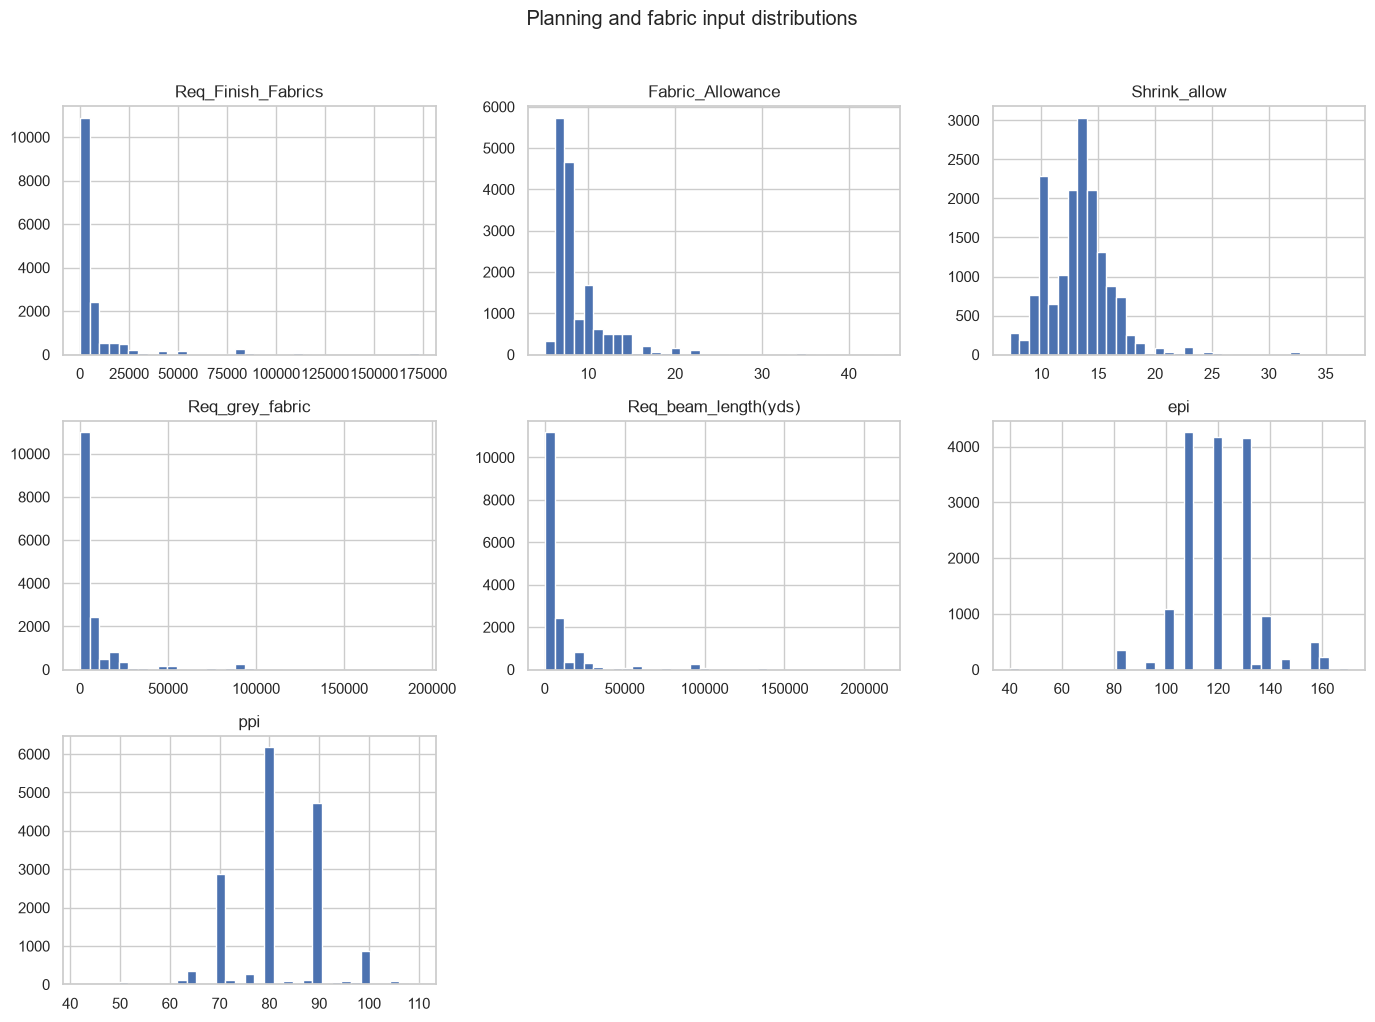

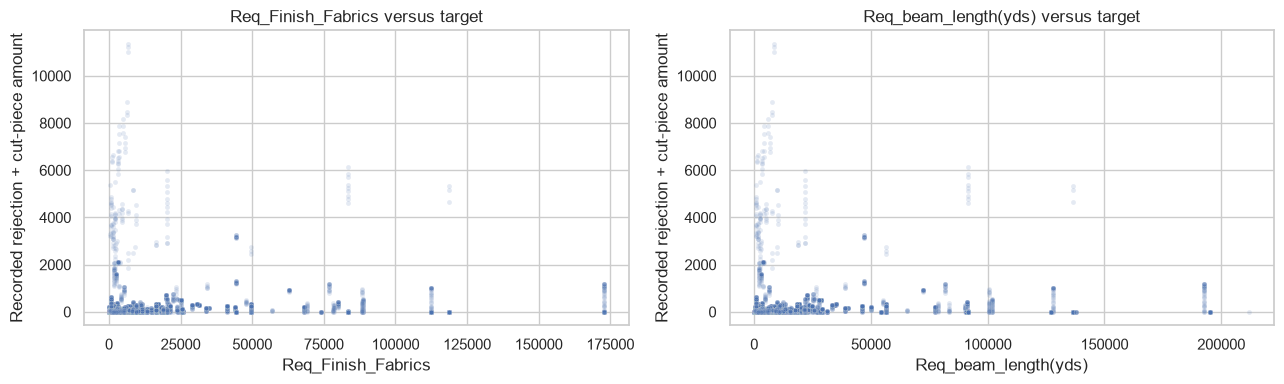

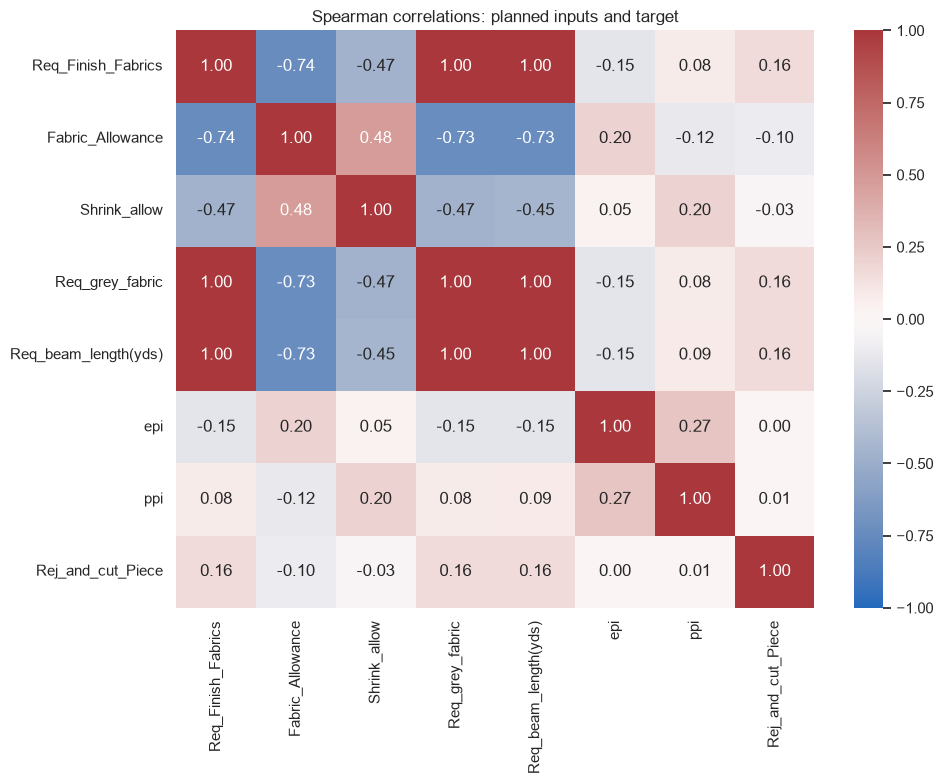

In [3]:
planned_features = [
    "Req_Finish_Fabrics",
    "Fabric_Allowance",
    "Shrink_allow",
    "Req_grey_fabric",
    "Req_beam_length(yds)",
    "epi",
    "ppi"
]

# Numeric conversion for inspection; report values that fail conversion
numeric_view = dev[planned_features + [target]].apply(
    pd.to_numeric, errors="coerce"
)

conversion_failures = (
    dev[planned_features].notna()
    & numeric_view[planned_features].isna()
).sum()

print("Non-missing entries that failed numeric conversion:")
display(conversion_failures)
display(numeric_view[planned_features].describe().T)

numeric_view[planned_features].hist(
    bins=35, figsize=(14, 10), layout=(3, 3)
)
plt.suptitle("Planning and fabric input distributions", y=1.02)
plt.tight_layout()
plt.savefig(
    figures / "eda_input_distributions.png",
    dpi=160, bbox_inches="tight"
)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, feature in zip(
    axes, ["Req_Finish_Fabrics", "Req_beam_length(yds)"]
):
    sns.scatterplot(
        data=numeric_view,
        x=feature,
        y=target,
        alpha=0.15,
        s=12,
        ax=ax
    )
    ax.set_ylabel("Recorded rejection + cut-piece amount")
    ax.set_title(f"{feature} versus target")

fig.tight_layout()
fig.savefig(figures / "eda_planned_quantity_relationships.png", dpi=160)
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(
    numeric_view.corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Spearman correlations: planned inputs and target")
plt.tight_layout()
plt.savefig(figures / "eda_correlations.png", dpi=160)
plt.show()

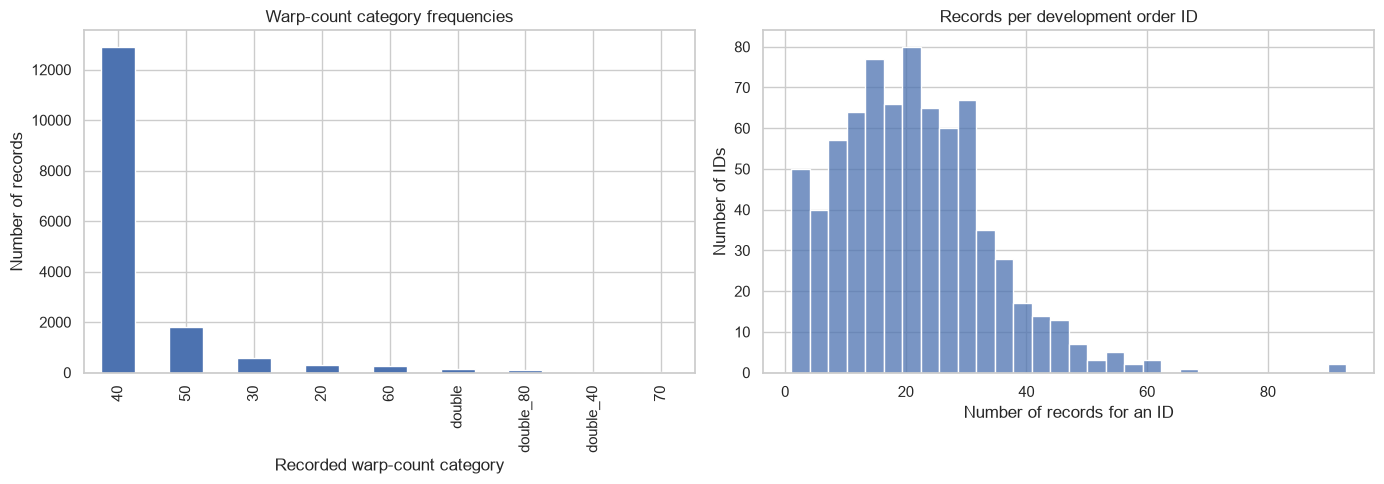

,record_count,median,mean
warp_count,,,
20,285,4.0,20.768421
30,572,26.0,89.375874
40,12907,17.0,103.509259
50,1820,13.0,94.944505
60,253,12.0,385.304348
70,5,3.0,3.000000
double,154,228.0,203.084416
double_40,34,24.0,15.411765
double_80,109,19.0,40.256881


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

dev["warp_count"].astype("string").fillna("Missing").value_counts().plot.bar(
    ax=axes[0]
)
axes[0].set_title("Warp-count category frequencies")
axes[0].set_xlabel("Recorded warp-count category")
axes[0].set_ylabel("Number of records")

records_per_id = dev.groupby("ID").size()
sns.histplot(x=records_per_id, bins=30, ax=axes[1])
axes[1].set_title("Records per development order ID")
axes[1].set_xlabel("Number of records for an ID")
axes[1].set_ylabel("Number of IDs")

fig.tight_layout()
fig.savefig(figures / "eda_categories_and_order_records.png", dpi=160)
plt.show()

display(
    dev.groupby("warp_count", dropna=False)[target]
    .agg(["size", "median", "mean"])
    .rename(columns={"size": "record_count"})
)